**Tarea 6.6**: Se quiere interpolar la función

$$
f(x)=\sinh(x)
$$

en el intervalo

$$
[-5,5]
$$

utilizando cinco puntos equidistantes.

Según los apuntes, dados $n+1$ puntos existe un único polinomio interpolante de grado $n$:

$$
P(x)=\sum_{i=0}^n f(x_i)L_i(x),
$$

donde

$$
L_i(x)=
\prod_{\substack{j=0\\j\neq i}}^n
\frac{x-x_j}{x_i-x_j}.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Los cinco puntos equidistantes entre $-5$ y $5$ son

$$
x_i=-5,\,-2.5,\,0,\,2.5,\,5.
$$

En cada uno se calcula

$$
f(x_i)=\sinh(x_i).
$$

In [15]:
xp = np.linspace(-5, 5, 5)
puntos = [(xi, np.sinh(xi)) for xi in xp]

print(puntos)

[(np.float64(-5.0), np.float64(-74.20321057778875)), (np.float64(-2.5), np.float64(-6.0502044810397875)), (np.float64(0.0), np.float64(0.0)), (np.float64(2.5), np.float64(6.0502044810397875)), (np.float64(5.0), np.float64(74.20321057778875))]


In [3]:
def lagrange(x, puntos):

    Lis = np.ones(len(puntos))
    fs = np.ones(len(puntos))

    for i in range(len(puntos)):
        fs[i] = puntos[i][1]

        for j in range(len(puntos)):
            if j != i:
                Lis[i] *= (x - puntos[j][0]) / (puntos[i][0] - puntos[j][0])

    return sum(fs * Lis)

Ahora graficamos la función

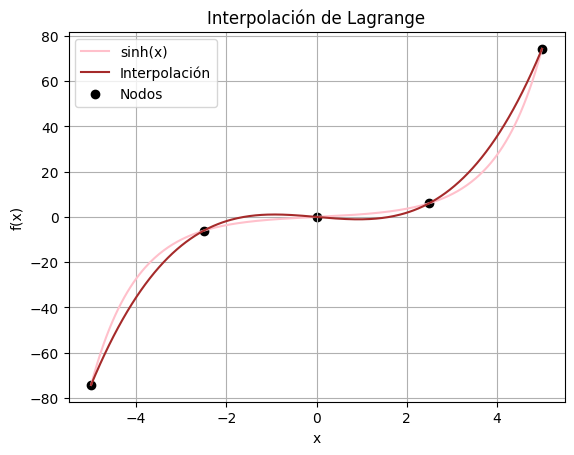

In [23]:
x = np.linspace(-5, 5, 300)

exacta = np.sinh(x)
interpolada = np.array([lagrange(xi, puntos) for xi in x])

plt.plot(x, exacta, color='pink', label="sinh(x)")
plt.plot(x, interpolada, color='brown', label="Interpolación")
plt.scatter(xp, np.sinh(xp), color='black', label='Nodos')

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title('Interpolación de Lagrange')
plt.grid()
plt.legend()
plt.show()

Para estimar el error, como se utilizan cinco puntos, el polinomio interpolante tiene grado máximo $4$. Por lo tanto, la fórmula del error es

$$
f(x)-P(x)=
\frac{f^{(5)}(\xi)}{5!}
\prod_{i=0}^{4}(x-x_i).
$$

Como

$$
f(x)=\sinh(x),
$$

se tiene

$$
f^{(5)}(x)=\cosh(x).
$$

En el intervalo $[-5,5]$,

$$
|\cosh(x)|\leq \cosh(5).
$$

Por lo tanto, una cota para el error es

$$
E_{\mathrm{est}}(x)=
\frac{\cosh(5)}{5!}
\left|
\prod_{i=0}^4(x-x_i)
\right|.
$$

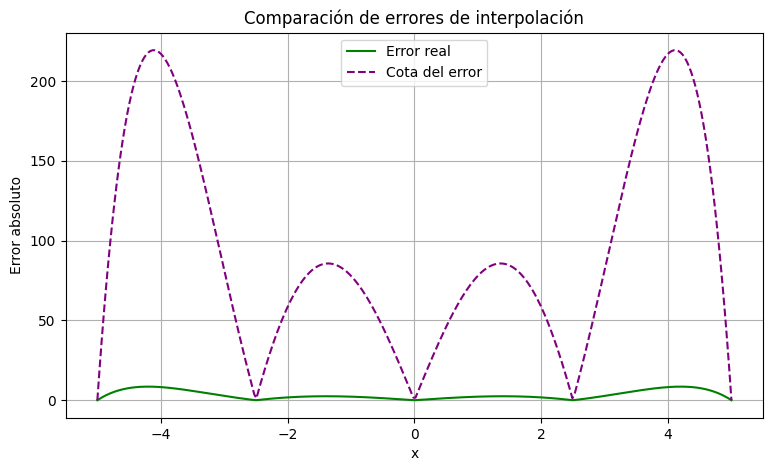

In [21]:
from math import factorial

M = np.cosh(5)
error_estimado = []

for xi in x:
    producto = np.prod([xi - nodo for nodo in xp])
    error_estimado.append(M / factorial(5) * abs(producto))

# Error real de la interpolación
error_real = np.abs(exacta - interpolada)

plt.figure(figsize=(9, 5))

plt.plot(x, error_real, color='green', label='Error real')
plt.plot(x, error_estimado, '--', color='purple', label='Cota del error')

plt.xlabel('x')
plt.ylabel('Error absoluto')
plt.title('Comparación de errores de interpolación')
plt.grid()
plt.legend()
plt.show()

## Análisis

El polinomio interpolante pasa exactamente por los cinco puntos utilizados, por lo que el error es cero en

$$
x=-5,\,-2.5,\,0,\,2.5,\,5.
$$

Entre estos puntos aparece una diferencia entre $\sinh(x)$ y el polinomio interpolante.

La estimación del error también se hace cero en los puntos de interpolación debido al factor

$$
\prod_{i=0}^4(x-x_i).
$$

La curva del error estimado no tiene por qué coincidir exactamente con el error real, ya que se utilizó el máximo valor de la quinta derivada en todo el intervalo:

$$
\max_{[-5,5]}|\cosh(x)|=\cosh(5).
$$

Por esta razón, el error estimado funciona como una cota para el error real.

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.


